# Predicting Online Shopper Purchase Intent

**M.Tech (AIML) — Machine Learning, Assignment 2**

This notebook develops and compares five classifiers on the UCI *Online Shoppers
Purchasing Intention* dataset. Each session on an e-commerce site is described by
17 behavioural and contextual features, and the task is to predict whether that
session ended in a purchase (`Revenue`).

The workflow below is the same code path used by `src/train_models.py`, so the
artifacts in `model/` and the figures here come from one shared implementation.

In [1]:
import sys
from pathlib import Path

# Lets the notebook import the project package when launched from notebooks/.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)

from src.config import CATEGORICAL_FEATURES, FEATURE_COLUMNS, NUMERIC_FEATURES, TARGET_COLUMN
from src.train_models import load_sessions, carve_holdout, tune_and_fit
from src.metrics import score_classifier, METRIC_ORDER
from src.preprocessing import normalise_frame
from src.config import CLASSIFIER_REGISTRY

## 1. Load the raw sessions

In [2]:
sessions = load_sessions()
print("rows:", len(sessions), " columns:", sessions.shape[1])
print("feature columns:", len(FEATURE_COLUMNS))
sessions.head()

rows: 12205  columns: 18
feature columns: 17


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,0


In [3]:
print("missing values:", int(sessions.isna().sum().sum()))
print("duplicate rows removed during load:", 12330 - len(sessions))
sessions.dtypes.to_frame("dtype")

missing values: 0
duplicate rows removed during load: 125


,dtype
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


## 2. Target balance

Only about one session in six ends in a purchase. This imbalance is the single
most important property of the dataset — it is why accuracy alone is a poor
yardstick here, and why MCC and AUC carry the comparison later on.

Revenue
No purchase    10297
Purchase        1908
Name: count, dtype: int64
positive rate: 0.1563


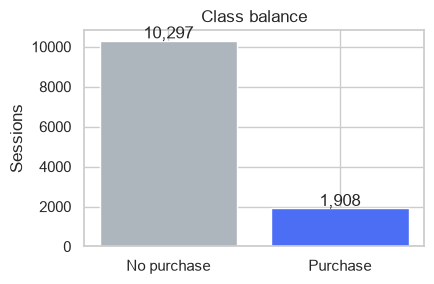

In [4]:
balance = sessions[TARGET_COLUMN].value_counts().rename({0: "No purchase", 1: "Purchase"})
print(balance)
print(f"positive rate: {sessions[TARGET_COLUMN].mean():.4f}")

fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(balance.index, balance.values, color=["#adb5bd", "#4c6ef5"])
ax.set_ylabel("Sessions")
ax.set_title("Class balance")
for i, v in enumerate(balance.values):
    ax.text(i, v + 120, f"{v:,}", ha="center")
plt.tight_layout()
plt.show()

## 3. How the numeric features separate the two classes

`PageValues` — the average value of the pages visited before the session —
stands out immediately. Sessions that convert spend time on pages with a much
higher assigned value, while bounce and exit rates move in the opposite
direction.

In [5]:
summary = sessions.groupby(TARGET_COLUMN)[NUMERIC_FEATURES].mean().T
summary.columns = ["No purchase", "Purchase"]
summary.round(3)

,No purchase,Purchase
Administrative,2.143,3.394
Administrative_Duration,74.635,119.483
Informational,0.457,0.786
Informational_Duration,30.603,57.611
ProductRelated,29.050,48.210
ProductRelated_Duration,1082.977,1876.210
BounceRates,0.023,0.005
ExitRates,0.046,0.020
PageValues,2.000,27.265
SpecialDay,0.069,0.023


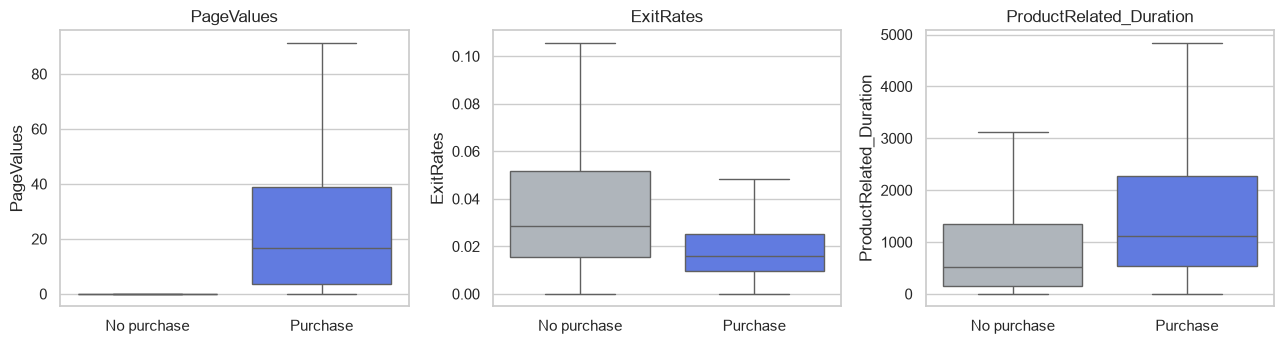

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, column in zip(axes, ["PageValues", "ExitRates", "ProductRelated_Duration"]):
    sns.boxplot(
        data=sessions, x=TARGET_COLUMN, y=column, ax=ax,
        palette=["#adb5bd", "#4c6ef5"], showfliers=False,
    )
    ax.set_xticklabels(["No purchase", "Purchase"])
    ax.set_xlabel("")
    ax.set_title(column)
plt.tight_layout()
plt.show()

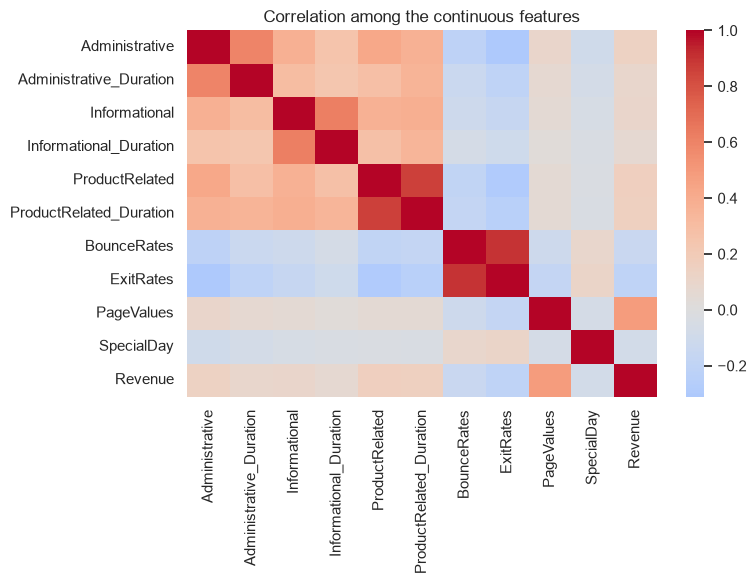

PageValues                 0.492
ProductRelated             0.156
ProductRelated_Duration    0.150
Administrative             0.136
Informational              0.094
Administrative_Duration    0.092
Informational_Duration     0.069
SpecialDay                -0.084
BounceRates               -0.145
ExitRates                 -0.204
Name: Revenue, dtype: float64

In [7]:
numeric_corr = sessions[NUMERIC_FEATURES + [TARGET_COLUMN]].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(numeric_corr, cmap="coolwarm", center=0, annot=False, ax=ax)
ax.set_title("Correlation among the continuous features")
plt.tight_layout()
plt.show()

numeric_corr[TARGET_COLUMN].drop(TARGET_COLUMN).sort_values(ascending=False).round(3)

## 4. Conversion rate across the categorical fields

`Month` and `VisitorType` both carry real signal: November converts far above
average, and returning visitors behave differently from first-time ones.

In [8]:
for column in ["Month", "VisitorType"]:
    rate = sessions.groupby(column)[TARGET_COLUMN].agg(["mean", "size"])
    rate.columns = ["conversion_rate", "sessions"]
    print(f"\n--- {column} ---")
    print(rate.sort_values("conversion_rate", ascending=False).round(3))


--- Month ---
       conversion_rate  sessions
Month                           
Nov              0.255      2982
Oct              0.209       549
Sep              0.192       448
Aug              0.176       433
Jul              0.153       432
Dec              0.127      1706
May              0.110      3329
Mar              0.103      1860
June             0.102       285
Feb              0.017       181

--- VisitorType ---
                   conversion_rate  sessions
VisitorType                                 
New_Visitor                  0.249      1693
Other                        0.198        81
Returning_Visitor            0.141     10431


## 5. Train / test split

A stratified 80/20 split keeps the purchase rate identical in both halves. The
held-out 20% is written to `test_data.csv` and is the file the Streamlit app
scores — the models never see it during fitting.

In [9]:
train_frame, holdout_frame = carve_holdout(sessions)
print("train rows:", len(train_frame), " holdout rows:", len(holdout_frame))
print(f"train purchase rate:   {train_frame[TARGET_COLUMN].mean():.4f}")
print(f"holdout purchase rate: {holdout_frame[TARGET_COLUMN].mean():.4f}")

train_x = normalise_frame(train_frame)[FEATURE_COLUMNS]
train_y = train_frame[TARGET_COLUMN]
holdout_x = normalise_frame(holdout_frame)[FEATURE_COLUMNS]
holdout_y = holdout_frame[TARGET_COLUMN]

train rows: 9764  holdout rows: 2441
train purchase rate:   0.1563
holdout purchase rate: 0.1565


## 6. Preprocessing

One `ColumnTransformer` handles both halves of the feature set:

* the ten continuous session metrics are standardised, which matters for the
  distance-based and margin-based learners (KNN, SVM) and for the convergence of
  logistic regression;
* the seven unordered label columns are one-hot encoded. `OperatingSystems`,
  `Browser`, `Region` and `TrafficType` are stored as integers in the source
  file but carry no ordering, so treating them as numbers would invent a
  relationship that does not exist.

The transformer is fitted inside each model's `Pipeline`, so it is persisted
alongside the estimator and the app can score a raw CSV with no manual prep.

In [10]:
from src.preprocessing import build_feature_pipeline

preview = build_feature_pipeline().fit(train_x)
print("columns after preprocessing:", preview.transform(train_x).shape[1])
print("one-hot expansion came from:", CATEGORICAL_FEATURES)

columns after preprocessing: 75
one-hot expansion came from: ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']


## 7. Fit all five classifiers

Each model is tuned with a 5-fold stratified grid search optimising **F1**, which
is the right target under imbalance — it refuses to reward a model that simply
predicts "no purchase" for everything. `class_weight` is part of the grid where
the estimator supports it, so the search decides for itself whether rebalancing
helps.

In [11]:
results = {}
fitted_models = {}

for key, label in CLASSIFIER_REGISTRY.items():
    estimator, chosen, elapsed = tune_and_fit(key, train_x, train_y)
    fitted_models[key] = estimator
    results[label] = score_classifier(estimator, holdout_x, holdout_y)
    tidy = {k.replace("learner__", ""): v for k, v in chosen.items()}
    print(f"{label:<24} {elapsed:6.1f}s   best params: {tidy}")

Logistic Regression         6.1s   best params: {'C': 0.1, 'class_weight': 'balanced'}


Decision Tree               2.7s   best params: {'class_weight': None, 'max_depth': 5, 'min_samples_leaf': 20}


K-Nearest Neighbours        2.0s   best params: {'n_neighbors': 5, 'weights': 'distance'}


Naive Bayes (Gaussian)      0.5s   best params: {'var_smoothing': 0.001}


Support Vector Machine     13.9s   best params: {'C': 1.0, 'class_weight': 'balanced'}


## 8. Comparison table

In [12]:
comparison = pd.DataFrame(results).T[METRIC_ORDER].round(4)
comparison.index.name = "ML Model Name"
comparison

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8619,0.9117,0.5414,0.7696,0.6357,0.5667
Decision Tree,0.9070,0.9321,0.7370,0.6309,0.6798,0.6284
K-Nearest Neighbours,0.8763,0.7935,0.6786,0.3979,0.5017,0.4568
Naive Bayes (Gaussian),0.6534,0.7939,0.2864,0.8141,0.4237,0.3200
Support Vector Machine,0.8800,0.9190,0.5906,0.7592,0.6644,0.5996


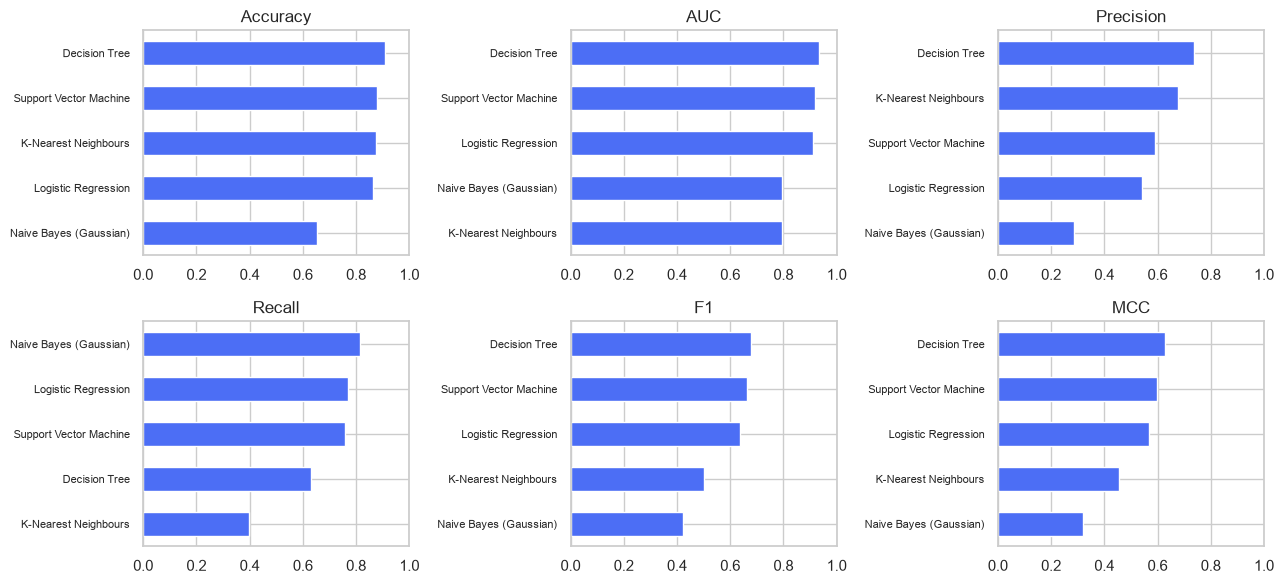

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, metric in zip(axes.ravel(), METRIC_ORDER):
    ordered = comparison[metric].sort_values()
    ax.barh(ordered.index, ordered.values, color="#4c6ef5", height=0.55)
    ax.set_xlim(0, 1)
    ax.set_title(metric)
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

## 9. Confusion matrices

The tables above compress a lot of behaviour into single numbers. The matrices
below show what each model actually does with the 382 purchasing sessions in the
held-out split.

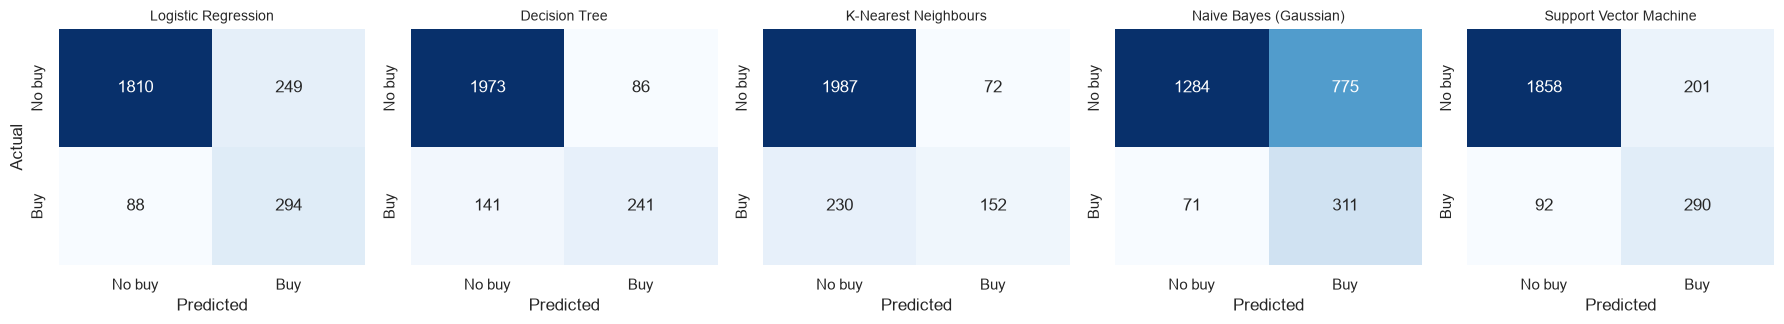

In [14]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 5, figsize=(18, 3.4))
for ax, (key, label) in zip(axes, CLASSIFIER_REGISTRY.items()):
    matrix = confusion_matrix(holdout_y, fitted_models[key].predict(holdout_x))
    sns.heatmap(
        matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["No buy", "Buy"], yticklabels=["No buy", "Buy"],
    )
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("Predicted")
    if ax is axes[0]:
        ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 10. ROC curves

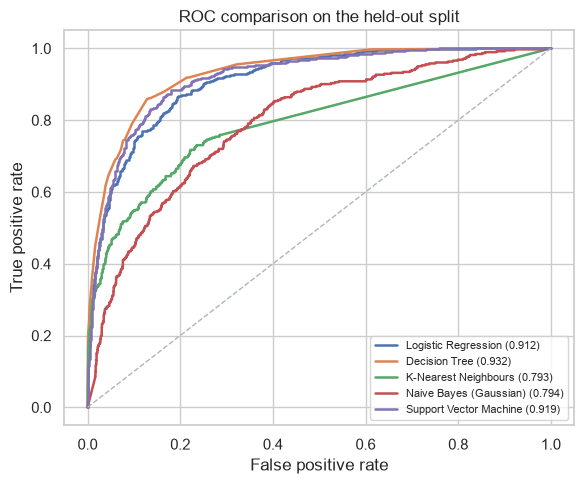

In [15]:
from sklearn.metrics import roc_curve
from src.metrics import positive_class_scores

fig, ax = plt.subplots(figsize=(6, 5))
for key, label in CLASSIFIER_REGISTRY.items():
    scores = positive_class_scores(fitted_models[key], holdout_x)
    fpr, tpr, _ = roc_curve(holdout_y, scores)
    ax.plot(fpr, tpr, linewidth=1.8, label=f"{label} ({comparison.loc[label, 'AUC']:.3f})")
ax.plot([0, 1], [0, 1], "--", color="#adb5bd", linewidth=1)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC comparison on the held-out split")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## 11. What the winning tree learned

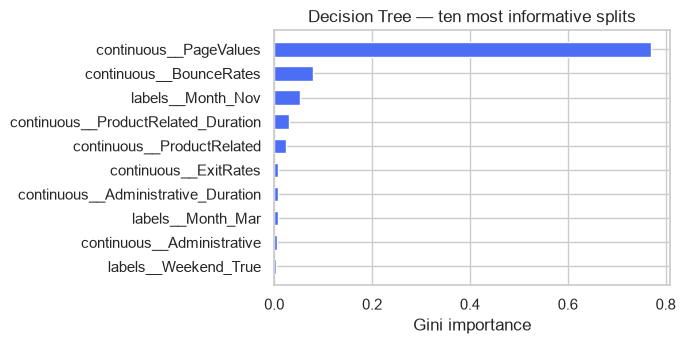

continuous__PageValues                 0.7705
continuous__BounceRates                0.0801
labels__Month_Nov                      0.0526
continuous__ProductRelated_Duration    0.0293
continuous__ProductRelated             0.0235
continuous__ExitRates                  0.0088
continuous__Administrative_Duration    0.0077
labels__Month_Mar                      0.0073
continuous__Administrative             0.0064
labels__Weekend_True                   0.0040
dtype: float64

In [16]:
tree = fitted_models["decision_tree"]
names = tree.named_steps["prepare"].get_feature_names_out()
importance = (
    pd.Series(tree.named_steps["learner"].feature_importances_, index=names)
    .sort_values(ascending=False)
    .head(10)
)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(importance.index[::-1], importance.values[::-1], color="#4c6ef5", height=0.6)
ax.set_xlabel("Gini importance")
ax.set_title("Decision Tree — ten most informative splits")
plt.tight_layout()
plt.show()

importance.round(4)

## 12. Conclusion

The **Decision Tree** wins this dataset on accuracy, AUC, F1 and MCC. Its
advantage comes from `PageValues`, which accounts for roughly 77% of its split
importance and has a sharp, threshold-like relationship with purchasing that an
axis-aligned split captures exactly. Depth-5 pruning with a minimum of 20
samples per leaf keeps it from memorising noise.

The **SVM** and **logistic regression** both land in a high-recall regime after
the grid search picked `class_weight="balanced"` for them: they catch around
three-quarters of real purchases but flag roughly twice as many sessions as
actually convert. **KNN** goes the other way, being conservative and missing
most purchases, because in a 70-plus dimensional mostly one-hot space, distance
loses its discriminating power. **Gaussian Naive Bayes** performs worst by a
clear margin — its independence assumption is badly violated by the strongly
correlated page-count and duration pairs, and the Gaussian likelihood is a poor
fit for one-hot columns and for the heavily zero-inflated `PageValues`.

The trained pipelines are saved under `model/` and served by `app.py`.